# Milestone 2 — Modellreife & Validierung

Aufbauend auf der Baseline (`baseline_model.ipynb`, siehe `MILESTONE1_REPORT.md`: Crop Balanced Accuracy 0.778, Stage 0.769). Dieses Notebook überarbeitet die Preprocessing-Pipeline (Spektral-Interpolation statt globalem Median, zyklisches Month-Encoding, Stratifizierung auf Crop+Stage), ergänzt **Feature Engineering** (Vegetationsindizes, Red-Edge, Gradienten, Spektral-Statistiken — übernommen und überarbeitet aus `features.ipynb`) und ersetzt den einfachen Train/Test-Split durch 5-fache Cross-Validation inkl. Modellvergleich (RandomForest vs. HistGradientBoosting vs. MLP), Overfitting-Check (Train vs. CV), **Strategievergleich** (separate Modelle vs. gemeinsames Label `Crop|Stage`) und Fehleranalyse (Confusion Matrix pro Klasse).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
df = pd.read_csv('train.csv')

## Preprocessing v2

**Spektral-NaN-Handling:** Wie in M1 werden die 67 komplett leeren Spektralband-Spalten verworfen. Für die verbleibenden 6 Spalten mit vereinzelten Lücken (max. 24 von 5591 Zeilen) nutzen wir statt globalem Spalten-Median eine **zeilenweise lineare Interpolation entlang der Wellenlänge**: die Spaltennamen (`X<nm>`) kodieren die Wellenlänge, Reflektanzspektren verlaufen glatt über benachbarte Bänder, daher lässt sich eine fehlende Bande besser aus den Nachbarbändern *derselben Messung* schätzen als aus dem Median über alle Messungen. Die Interpolation ist zeilenlokal (nutzt nur Werte derselben Zeile) → kein Leakage zwischen Train/Test, kann also vor dem Split angewendet werden. Ein `SimpleImputer(median)` bleibt zusätzlich als Absicherung in der Pipeline für etwaige Restfälle (Rand-NaNs ohne Nachbarn in einer Richtung).

In [2]:
spec_cols = [c for c in df.columns if c.startswith('X')]
na_frac = df[spec_cols].isna().mean()
usable_spec_cols = sorted([c for c in spec_cols if na_frac[c] < 1.0], key=lambda c: int(c[1:]))
print(f'Nutzbare Spektralbaender: {len(usable_spec_cols)} von {len(spec_cols)}')

df[usable_spec_cols] = df[usable_spec_cols].interpolate(method='linear', axis=1, limit_direction='both')
remaining_na = df[usable_spec_cols].isna().sum().sum()
print('Verbleibende NaNs in Spektralbaendern nach Interpolation:', remaining_na)
assert remaining_na == 0, 'Unerwartete NaNs nach Interpolation -- SimpleImputer-Sicherheitsnetz greift in der Pipeline'

Nutzbare Spektralbaender: 131 von 198
Verbleibende NaNs in Spektralbaendern nach Interpolation: 0


## Feature Engineering

Aus den interpolierten Spektren werden zusätzliche, **rein zeilenlokale** Features berechnet (nutzen nur Werte derselben Messung → kein Leakage, vor dem Split zulässig und später 1:1 auf `test.csv` anwendbar). Bänder werden per nächstgelegener Wellenlänge gewählt, Reflektanz liegt in Prozent (0–93).

Übernommen aus `features.ipynb`:
- **Spektral-Statistiken:** mean, std (neu), max, min, Amplitude; Position von Max/Min als **Wellenlänge** (statt Bandabstand, der über die entfernten Wasserbänder hinweg verzerrt ist).
- **Vegetationsindizes:** NDVI, Simple Ratio NIR/Rot, NDMI (NIR/SWIR1), NBR (NIR/SWIR2), ND NIR2/SWIR1, EVI (Konstante auf Prozent-Skala angepasst).
- **Gradienten:** max. positive/negative Steigung und totale Variation — hier **pro nm** (`Δ Reflektanz / Δ λ`), sonst dominieren die Sprünge an den Lücken (923→983, 1094→1175, 1316→1518, 1760→2063 nm).
- **AEZ One-Hot:** für das MLP sinnvoll (AEZ ist kategorial), für Bäume neutral.

Neu (domänenspezifisch; die Aufgabenstellung betont Red-Edge und SWIR, zielt v. a. auf die schwachen Reife-/Erntestadien):
- **Red-Edge:** NDRE (790/720), CI red-edge (783/712 − 1), Red-Edge-Position (lineare Interpolation nach Guyot & Baret, 670/700/740/780 nm) — Chlorophyllgehalt, verschiebt sich mit dem Wachstumsstadium.
- **PSRI** (680 − 500)/750 — Plant Senescence Reflectance Index, Seneszenz/Reife.
- **PRI** (531/570) — Photosynthese-Effizienz; **NDWI nach Gao** (860/1240) — Blattwassergehalt.

Bewusst **nicht** übernommen aus `features.ipynb`: die 46 normierten Differenzen/Ratios an Prozent-Positionen des Spektrums (b10…b90 — Positionen ohne physikalische Bedeutung, mehrere davon Duplikate bzw. Kehrwerte voneinander; die Domänen-Indizes decken das fachlich begründet ab) und die Breiten der Hoch-/Tiefbereiche (in Bandanzahl gemessen, über die Lücken hinweg irreführend).

In [3]:
def add_features(df, cols):
    """Zeilenlokale Spektral-Features. cols: nach Wellenlaenge sortierte, interpolierte Bandspalten."""
    S = df[cols].to_numpy(float)
    wl = np.array([int(c[1:]) for c in cols], dtype=float)
    def b(nm):  # Reflektanz des Bandes mit der naechsten Wellenlaenge
        return S[:, np.abs(wl - nm).argmin()]
    def nd(a, c):
        return (a - c) / (a + c)

    blue, red, nir, nir2, swir1, swir2 = b(490), b(660), b(850), b(1100), b(1640), b(2200)
    slope = np.diff(S, axis=1) / np.diff(wl)  # pro nm
    r670, r700, r740, r780 = b(670), b(700), b(740), b(780)
    f = {
        # Statistiken
        'spec_mean': S.mean(1), 'spec_std': S.std(1), 'spec_max': S.max(1), 'spec_min': S.min(1),
        'spec_amplitude': S.max(1) - S.min(1), 'wl_of_max': wl[S.argmax(1)], 'wl_of_min': wl[S.argmin(1)],
        # Vegetationsindizes
        'NDVI': nd(nir, red), 'SR_NIR_Red': nir / red, 'NDMI': nd(nir, swir1), 'NBR': nd(nir, swir2),
        'ND_NIR2_SWIR1': nd(nir2, swir1),
        'EVI': 2.5 * (nir - red) / (nir + 6 * red - 7.5 * blue + 100),  # Reflektanz in %, daher +100 statt +1
        # Gradienten
        'max_pos_slope': slope.max(1), 'max_neg_slope': slope.min(1), 'total_variation': np.abs(slope).sum(1),
        # Red-Edge, Seneszenz, Wasser
        'NDRE': nd(b(790), b(720)), 'CI_rededge': b(783) / b(712) - 1,
        'REP': 700 + 40 * ((r670 + r780) / 2 - r700) / (r740 - r700),
        'PSRI': (b(680) - b(500)) / b(750), 'PRI': nd(b(531), b(570)), 'NDWI_Gao': nd(b(860), b(1240)),
    }
    return pd.DataFrame(f, index=df.index).replace([np.inf, -np.inf], np.nan)

eng = add_features(df, usable_spec_cols)
aez_onehot = pd.get_dummies(df['AEZ'], prefix='AEZ', dtype=float)
eng_cols = list(eng.columns) + list(aez_onehot.columns)
df = pd.concat([df, eng, aez_onehot], axis=1).copy()
print(f'{eng.shape[1]} Spektral-Features + {aez_onehot.shape[1]} AEZ-One-Hot-Spalten, NaN/inf: {int(eng.isna().sum().sum())}')
eng.describe().T[['mean', 'min', 'max']].round(3)

22 Spektral-Features + 7 AEZ-One-Hot-Spalten, NaN/inf: 0


,mean,min,max
spec_mean,26.639,12.034,50.618
spec_std,11.968,2.157,28.258
spec_max,48.865,18.689,93.232
spec_min,9.592,0.252,27.963
spec_amplitude,39.273,10.244,86.671
wl_of_max,1128.179,437.000,2143.000
wl_of_min,1748.666,447.000,2345.000
NDVI,0.485,0.059,0.877
SR_NIR_Red,4.232,1.127,15.273
NDMI,0.178,-0.301,0.614


**Month-Encoding:** `Month` reicht im Datensatz nur von 5 (Mai) bis 10 (Oktober) — es gibt keinen Jahreswechsel (Dez→Jan), den eine zyklische Kodierung eigentlich auflösen soll. Zyklisches Encoding ist hier also theoretisch nicht zwingend notwendig; wir testen es trotzdem empirisch per Cross-Validation gegen die einfache numerische Variante (siehe Modellvergleich unten) und werten anhand des CV-Scores, ob es einen messbaren Unterschied macht.

In [4]:
print('Month-Wertebereich:', df['Month'].min(), '-', df['Month'].max())
df['Month_sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_cos'] = np.cos(2 * np.pi * df['Month'] / 12)

Month-Wertebereich: 5 - 10


**Kombinierter Stratifizierungs-Key:** Die Baseline stratifizierte nur auf `Crop` — laut Feedback soll `Stage` ebenfalls berücksichtigt werden. Da `Stage` inhaltlich eine Unterkategorie innerhalb von `Crop` ist (vgl. Aufgabenstellung, z. B. `corn_early`), bilden wir den kombinierten Key `Crop_Stage` und stratifizieren darauf — das erhält gleichzeitig die Verteilung von `Crop` und von `Stage` in Train/Test und in jedem CV-Fold.

In [5]:
df['Crop_Stage'] = df['Crop'] + '|' + df['Stage']  # '|' als Trenner: Stage-Namen enthalten selbst '_'
combo_counts = df['Crop_Stage'].value_counts()
print(f"{len(combo_counts)} Crop x Stage Kombinationen, kleinste: {combo_counts.idxmin()} mit {combo_counts.min()} Zeilen")
pd.crosstab(df['Crop'], df['Stage'])

23 Crop x Stage Kombinationen, kleinste: cotton|Harvest mit 11 Zeilen


Stage,Critical,Early_Mid,Emerge_VEarly,Harvest,Late,Mature_Senesc
Crop,,,,,,
corn,675,212,152,102,557,399
cotton,158,253,172,11,0,65
rice,0,52,0,0,41,0
soybean,652,465,106,67,233,146
winter_wheat,56,0,608,0,30,379


## Split

Hauptsplit bleibt 70/30 (Vergleichbarkeit mit M1), jetzt aber stratifiziert auf `Crop_Stage`. Zusätzlich prüfen wir kurz, ob andere Split-Verhältnisse (80/20, 90/10) das Ergebnis spürbar verändern.

In [6]:
feature_cols_plain = usable_spec_cols + ['AEZ', 'Month']
feature_cols_cyclic = usable_spec_cols + ['AEZ', 'Month_sin', 'Month_cos']
feature_cols_fe = usable_spec_cols + ['Month'] + eng_cols

y_crop = df['Crop']
y_stage = df['Stage']
combo = df['Crop_Stage']

train_idx, test_idx = train_test_split(df.index, test_size=0.3, stratify=combo, random_state=RANDOM_STATE)

feature_sets = {
    name: {'train': df.loc[train_idx, cols], 'test': df.loc[test_idx, cols]}
    for name, cols in [('plain_month', feature_cols_plain), ('cyclic_month', feature_cols_cyclic), ('plain_month+fe', feature_cols_fe)]
}

y_crop_train, y_crop_test = y_crop.loc[train_idx], y_crop.loc[test_idx]
y_stage_train, y_stage_test = y_stage.loc[train_idx], y_stage.loc[test_idx]
combo_train, combo_test = combo.loc[train_idx], combo.loc[test_idx]
targets = {'Crop': y_crop_train, 'Stage': y_stage_train}

for name, fs in feature_sets.items():
    print(f"{name:15s} Train: {fs['train'].shape}  Test: {fs['test'].shape}")

plain_month     Train: (3913, 133)  Test: (1678, 133)
cyclic_month    Train: (3913, 134)  Test: (1678, 134)
plain_month+fe  Train: (3913, 161)  Test: (1678, 161)


**Sensitivität gegenüber Split-Verhältnis:** Schnelle Kontrolle mit RandomForest (Default-Hyperparameter, plain Month), ob 70/30 gegenüber anderen gängigen Verhältnissen stark abweicht.

In [7]:
def quick_pipeline():
    return Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('clf', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE)),
    ])

ratio_rows = []
for test_size in [0.3, 0.2, 0.1]:
    tr_idx, te_idx = train_test_split(df.index, test_size=test_size, stratify=combo, random_state=RANDOM_STATE)
    crop_fit = quick_pipeline().fit(df.loc[tr_idx, feature_cols_plain], y_crop.loc[tr_idx])
    stage_fit = quick_pipeline().fit(df.loc[tr_idx, feature_cols_plain], y_stage.loc[tr_idx])
    ratio_rows.append({
        'test_size': test_size,
        'crop_balanced_accuracy': balanced_accuracy_score(y_crop.loc[te_idx], crop_fit.predict(df.loc[te_idx, feature_cols_plain])),
        'stage_balanced_accuracy': balanced_accuracy_score(y_stage.loc[te_idx], stage_fit.predict(df.loc[te_idx, feature_cols_plain])),
    })

ratio_results = pd.DataFrame(ratio_rows)
ratio_results

,test_size,crop_balanced_accuracy,stage_balanced_accuracy
0,0.3,0.809012,0.779478
1,0.2,0.789022,0.789190
2,0.1,0.803968,0.809342


## Cross-Validation & Modellvergleich

5-fache `StratifiedKFold` auf dem `Crop_Stage`-Key des Trainingssplits — dieselbe Fold-Einteilung wird für alle Modelle und Zielgrößen verwendet. Verglichen werden `RandomForestClassifier` (Baseline-Konfiguration), `HistGradientBoostingClassifier` (scikit-learn, kein Zusatzpaket) und ein `MLPClassifier`, auf drei Feature-Sets: Rohbänder mit plain bzw. zyklischem Month und Rohbänder + Feature Engineering (`plain_month+fe`). Der Vergleich Rohbänder vs. `+fe` ist die Ablation, ob das Feature Engineering etwas bringt.

Das MLP läuft aus Laufzeitgründen nur auf dem `+fe`-Set (es profitiert als einziges Modell von One-Hot-AEZ und Skalierung, und auf Rohbändern gibt es bereits RF/HGB als Referenz); `early_stopping` hält die Trainingszeit klein.

**Overfitting-Check:** `return_train_score=True` liefert zusätzlich die Balanced Accuracy auf den Trainingsfolds; `gap` = Train − CV. Eine hohe Train-Accuracy allein ist bei Bäumen normal — entscheidend ist ein hoher, stabiler CV-Score.

In [8]:
def make_pipe(clf):
    return Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler()), ('clf', clf)])

model_factories = {
    'RandomForest': lambda: RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    'HistGradientBoosting': lambda: HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    'MLP': lambda: MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-3, max_iter=300, early_stopping=True,
                                 random_state=RANDOM_STATE),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_folds = list(skf.split(feature_sets['plain_month']['train'], combo_train))

cv_rows = []
for model_name, factory in model_factories.items():
    for feat_name, feat in feature_sets.items():
        if model_name == 'MLP' and feat_name != 'plain_month+fe':
            continue
        for target_name, y_target in targets.items():
            scores = cross_validate(make_pipe(factory()), feat['train'], y_target, cv=cv_folds,
                                    scoring=['balanced_accuracy', 'f1_macro'], return_train_score=True, n_jobs=-1)
            cv_rows.append({
                'model': model_name,
                'feature_set': feat_name,
                'target': target_name,
                'cv_balanced_accuracy_mean': scores['test_balanced_accuracy'].mean(),
                'cv_balanced_accuracy_std': scores['test_balanced_accuracy'].std(),
                'cv_f1_macro_mean': scores['test_f1_macro'].mean(),
                'gap': scores['train_balanced_accuracy'].mean() - scores['test_balanced_accuracy'].mean(),
            })
            print(model_name, feat_name, target_name, f"cv_bacc={cv_rows[-1]['cv_balanced_accuracy_mean']:.3f}", flush=True)

cv_results = pd.DataFrame(cv_rows).sort_values(['target', 'cv_balanced_accuracy_mean'], ascending=[True, False])
cv_results.round(3)

RandomForest plain_month Crop cv_bacc=0.805
RandomForest plain_month Stage cv_bacc=0.768
RandomForest cyclic_month Crop cv_bacc=0.809
RandomForest cyclic_month Stage cv_bacc=0.783
RandomForest plain_month+fe Crop cv_bacc=0.841
RandomForest plain_month+fe Stage cv_bacc=0.797
HistGradientBoosting plain_month Crop cv_bacc=0.883
HistGradientBoosting plain_month Stage cv_bacc=0.852
HistGradientBoosting cyclic_month Crop cv_bacc=0.882
HistGradientBoosting cyclic_month Stage cv_bacc=0.853
HistGradientBoosting plain_month+fe Crop cv_bacc=0.897
HistGradientBoosting plain_month+fe Stage cv_bacc=0.883
MLP plain_month+fe Crop cv_bacc=0.884
MLP plain_month+fe Stage cv_bacc=0.829


,model,feature_set,target,cv_balanced_accuracy_mean,cv_balanced_accuracy_std,cv_f1_macro_mean,gap
10,HistGradientBoosting,plain_month+fe,Crop,0.897,0.014,0.895,0.103
12,MLP,plain_month+fe,Crop,0.884,0.036,0.874,0.035
6,HistGradientBoosting,plain_month,Crop,0.883,0.021,0.887,0.117
8,HistGradientBoosting,cyclic_month,Crop,0.882,0.026,0.888,0.118
4,RandomForest,plain_month+fe,Crop,0.841,0.032,0.852,0.159
2,RandomForest,cyclic_month,Crop,0.809,0.023,0.829,0.191
0,RandomForest,plain_month,Crop,0.805,0.021,0.823,0.195
11,HistGradientBoosting,plain_month+fe,Stage,0.883,0.009,0.890,0.117
9,HistGradientBoosting,cyclic_month,Stage,0.853,0.006,0.865,0.147
7,HistGradientBoosting,plain_month,Stage,0.852,0.010,0.863,0.148


### Strategievergleich: separate Modelle vs. gemeinsames Label

Die Aufgabenstellung verlangt den Vergleich der Modellierungsstrategien. Neben zwei separaten Modellen (Crop, Stage) wird ein **gemeinsames Modell auf `Crop|Stage`** (23 Klassen) trainiert. Damit der Vergleich fair ist, werden die Out-of-fold-Vorhersagen (`cross_val_predict`, dieselben 5 Folds) wieder in Crop und Stage zerlegt und mit derselben Metrik bewertet. Als Modell dient das MLP auf dem `+fe`-Set — dasselbe Modell wie bei den separaten MLP-Zeilen oben (HistGradientBoosting wäre bei 23 Klassen ~4× langsamer, da pro Klasse eigene Bäume gebaut werden).

In [9]:
X_fe_train, X_fe_test = feature_sets['plain_month+fe']['train'], feature_sets['plain_month+fe']['test']
joint_oof = pd.Series(cross_val_predict(make_pipe(model_factories['MLP']()), X_fe_train, combo_train, cv=cv_folds, n_jobs=-1),
                      index=X_fe_train.index).str.split('|', expand=True)

def cv_score(model, target):
    return cv_results.query("model == @model and feature_set == 'plain_month+fe' and target == @target")['cv_balanced_accuracy_mean'].item()

strategy_cv = pd.DataFrame([
    {'Strategie': 'separate MLPs', 'Crop CV bacc': cv_score('MLP', 'Crop'), 'Stage CV bacc': cv_score('MLP', 'Stage')},
    {'Strategie': 'gemeinsames MLP (Crop|Stage)', 'Crop CV bacc': balanced_accuracy_score(y_crop_train, joint_oof[0]),
     'Stage CV bacc': balanced_accuracy_score(y_stage_train, joint_oof[1])},
    {'Strategie': 'separate HistGradientBoosting (Referenz)', 'Crop CV bacc': cv_score('HistGradientBoosting', 'Crop'),
     'Stage CV bacc': cv_score('HistGradientBoosting', 'Stage')},
])
strategy_cv.round(3)

,Strategie,Crop CV bacc,Stage CV bacc
0,separate MLPs,0.884,0.829
1,gemeinsames MLP (Crop|Stage),0.909,0.861
2,separate HistGradientBoosting (Referenz),0.897,0.883


**Hyperparameter-Tuning:** Für die jeweils beste Modell/Encoding-Kombination pro Zielgröße (aus der CV-Tabelle oben) wird mit `RandomizedSearchCV` auf denselben 5 Folds leicht nachjustiert (kleines Suchraster, kein aufwändiges Grid).

In [10]:
param_grids = {
    'RandomForest': {'clf__n_estimators': [100, 200, 300], 'clf__max_depth': [None, 15, 30]},
    'HistGradientBoosting': {'clf__max_iter': [100, 200, 300], 'clf__learning_rate': [0.05, 0.1, 0.2], 'clf__max_depth': [None, 10, 20]},
    'MLP': {'clf__hidden_layer_sizes': [(128,), (128, 64), (256, 128)], 'clf__alpha': [1e-4, 1e-3, 1e-2],
            'clf__learning_rate_init': [5e-4, 1e-3]},
}

best_per_target = {}
for target_name in ['Crop', 'Stage']:
    top = cv_results[cv_results['target'] == target_name].iloc[0]
    model_name, feat_name = top['model'], top['feature_set']
    search = RandomizedSearchCV(make_pipe(model_factories[model_name]()), param_grids[model_name], n_iter=8, cv=cv_folds,
                                scoring='balanced_accuracy', random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(feature_sets[feat_name]['train'], targets[target_name])
    best_per_target[target_name] = {
        'model_name': model_name,
        'feat_name': feat_name,
        'best_estimator': search.best_estimator_,
        'best_params': search.best_params_,
        'cv_best_score': search.best_score_,
    }
    print(target_name, '->', model_name, feat_name, search.best_params_, f"CV balanced_accuracy={search.best_score_:.3f}")

Crop -> HistGradientBoosting plain_month+fe {'clf__max_iter': 200, 'clf__max_depth': 20, 'clf__learning_rate': 0.1} CV balanced_accuracy=0.907
Stage -> HistGradientBoosting plain_month+fe {'clf__max_iter': 300, 'clf__max_depth': 20, 'clf__learning_rate': 0.1} CV balanced_accuracy=0.891


## Finaler Fit & Fehleranalyse

Die getunten besten Modelle (bereits auf dem vollen Trainingssplit refittet durch `RandomizedSearchCV`) werden einmalig auf dem Test-Split (30 %, nie für CV/Tuning verwendet) ausgewertet — inkl. Confusion Matrix pro Klasse für die Fehleranalyse.

Crop - Modell: HistGradientBoosting (plain_month+fe) - Balanced Accuracy: 0.889, Macro F1: 0.886
              precision    recall  f1-score   support

        corn       0.94      0.94      0.94       630
      cotton       0.86      0.92      0.89       197
        rice       0.82      0.82      0.82        28
     soybean       0.92      0.90      0.91       501
winter_wheat       0.88      0.87      0.87       322

    accuracy                           0.91      1678
   macro avg       0.88      0.89      0.89      1678
weighted avg       0.91      0.91      0.91      1678



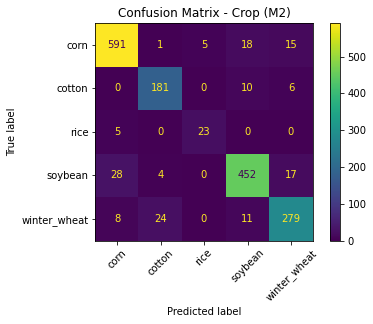

Stage - Modell: HistGradientBoosting (plain_month+fe) - Balanced Accuracy: 0.888, Macro F1: 0.891
               precision    recall  f1-score   support

     Critical       0.94      0.94      0.94       462
    Early_Mid       0.86      0.90      0.88       295
Emerge_VEarly       0.89      0.86      0.87       312
      Harvest       0.90      0.85      0.88        54
         Late       0.96      0.96      0.96       258
Mature_Senesc       0.83      0.83      0.83       297

     accuracy                           0.90      1678
    macro avg       0.90      0.89      0.89      1678
 weighted avg       0.90      0.90      0.90      1678



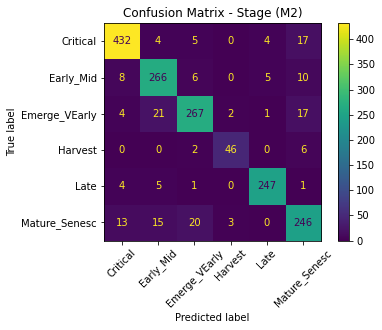

In [11]:
for target_name, y_test_sel in [('Crop', y_crop_test), ('Stage', y_stage_test)]:
    info = best_per_target[target_name]
    X_test_sel = feature_sets[info['feat_name']]['test']
    pred = info['best_estimator'].predict(X_test_sel)

    bacc = balanced_accuracy_score(y_test_sel, pred)
    f1 = f1_score(y_test_sel, pred, average='macro')
    info['test_bacc'] = bacc
    info['test_f1'] = f1

    print(f"{target_name} - Modell: {info['model_name']} ({info['feat_name']}) - Balanced Accuracy: {bacc:.3f}, Macro F1: {f1:.3f}")
    print(classification_report(y_test_sel, pred))

    ConfusionMatrixDisplay.from_predictions(y_test_sel, pred, xticks_rotation=45)
    plt.title(f'Confusion Matrix - {target_name} (M2)')
    plt.show()

**Gemeinsames Label auf dem Test-Split** (ungetuntes MLP, `+fe`), zerlegt in Crop und Stage — zum Strategievergleich.

In [12]:
joint_model = make_pipe(model_factories['MLP']()).fit(X_fe_train, combo_train)
joint_pred = pd.Series(joint_model.predict(X_fe_test), index=X_fe_test.index).str.split('|', expand=True)
joint_test = {}
for i, (target_name, y_true) in enumerate([('Crop', y_crop_test), ('Stage', y_stage_test)]):
    joint_test[target_name] = (balanced_accuracy_score(y_true, joint_pred[i]), f1_score(y_true, joint_pred[i], average='macro'))
    print(f'Joint-MLP {target_name}: Balanced Accuracy {joint_test[target_name][0]:.3f}, Macro F1 {joint_test[target_name][1]:.3f}')

Joint-MLP Crop: Balanced Accuracy 0.893, Macro F1 0.889
Joint-MLP Stage: Balanced Accuracy 0.874, Macro F1 0.873


## Zusammenfassung & Vergleich ggü. Baseline

In [13]:
rows = []
for target_name, m1_bacc, m1_f1, m2_bacc, m2_f1 in [('Crop', 0.778, 0.810, 0.877, 0.882), ('Stage', 0.769, 0.788, 0.874, 0.877)]:
    info = best_per_target[target_name]
    rows += [
        {'Zielgroesse': target_name, 'Modell': 'M1 Baseline (RandomForest)', 'Balanced Accuracy': m1_bacc, 'Macro F1': m1_f1},
        {'Zielgroesse': target_name, 'Modell': 'M2 ohne FE (HistGradientBoosting, Rohbaender)', 'Balanced Accuracy': m2_bacc, 'Macro F1': m2_f1},
        {'Zielgroesse': target_name, 'Modell': f"M2 final ({info['model_name']}, {info['feat_name']}, getunt)",
         'Balanced Accuracy': info['test_bacc'], 'Macro F1': info['test_f1']},
        {'Zielgroesse': target_name, 'Modell': 'Gemeinsames Label (MLP, plain_month+fe)',
         'Balanced Accuracy': joint_test[target_name][0], 'Macro F1': joint_test[target_name][1]},
    ]
summary = pd.DataFrame(rows)
summary.round(3)

,Zielgroesse,Modell,Balanced Accuracy,Macro F1
0,Crop,M1 Baseline (RandomForest),0.778,0.810
1,Crop,"M2 ohne FE (HistGradientBoosting, Rohbaender)",0.877,0.882
2,Crop,"M2 final (HistGradientBoosting, plain_month+fe...",0.889,0.886
3,Crop,"Gemeinsames Label (MLP, plain_month+fe)",0.893,0.889
4,Stage,M1 Baseline (RandomForest),0.769,0.788
5,Stage,"M2 ohne FE (HistGradientBoosting, Rohbaender)",0.874,0.877
6,Stage,"M2 final (HistGradientBoosting, plain_month+fe...",0.888,0.891
7,Stage,"Gemeinsames Label (MLP, plain_month+fe)",0.874,0.873


**Beobachtungen**

- **Modellwahl bleibt der größte Hebel:** `HistGradientBoostingClassifier` schlägt `RandomForestClassifier` in der CV auf jedem Feature-Set deutlich (Rohbänder: Crop 0.88 vs. 0.81, Stage 0.85 vs. 0.77–0.78).
- **Feature Engineering bringt messbar etwas (Ablation, CV):** HistGradientBoosting Crop 0.883 → **0.897**, Stage 0.852 → **0.883** (+0.031, größter Effekt bei Stage); RandomForest Crop 0.805 → 0.841, Stage 0.768 → 0.797. Die Verbesserung liegt über der CV-Streuung (Std 0.006–0.03). Plausibel, da Red-Edge-/Seneszenz-Indizes (REP, NDRE, PSRI) gerade die Wachstumsstadien beschreiben und Baummodelle Verhältnisse zwischen Bändern nur schwer selbst lernen können.
- **Overfitting-Check (gap = Train − CV):** Bäume haben erwartungsgemäß eine große Lücke (HGB ~0.10–0.12, RF ~0.16–0.23), der CV-Score ist aber hoch und stabil, und das Feature Engineering verkleinert die Lücke leicht. Das MLP (early stopping) hat die kleinste Lücke (~0.04), liegt aber bei den separaten Modellen unter HGB.
- **Strategievergleich:** Ein **gemeinsames MLP auf `Crop|Stage`** ist besser als zwei separate MLPs (CV Crop 0.909 vs. 0.884, Stage 0.861 vs. 0.829). Die Stage-Information hilft bei Crop und umgekehrt. Für Crop ist es in der CV sogar besser als separates HGB (0.909 vs. 0.897), für Stage bleibt separates HGB vorne (0.883 vs. 0.861). Auf dem Test-Split bestätigt sich das: Joint-MLP Crop 0.893 (HGB 0.889, im Rauschen) und Stage 0.874 (HGB 0.888). Ein hierarchisches Modell oder ein gemeinsames HGB sind naheliegende nächste Schritte.
- **Zyklisches Month-Encoding bringt weiterhin nichts:** Der Unterschied plain vs. zyklisch liegt bei ±0.002 (HGB) und damit im Rauschen; `Month` läuft nur von 5 bis 10 ohne Jahreswechsel. Das FE-Set nutzt daher plain `Month`.
- **Split-Verhältnis spielt kaum eine Rolle:** 70/30, 80/20 und 90/10 liegen im Band 0.78–0.81 ohne klaren Trend; wir bleiben bei 70/30.
- **Finale Testset-Ergebnisse (getuntes HGB + FE, nie für CV/Tuning verwendet):** Crop Balanced Accuracy **0.889** (M2 ohne FE: 0.877, M1: 0.778), Macro F1 0.886. Stage Balanced Accuracy **0.888** (M2 ohne FE: 0.874, M1: 0.769), Macro F1 0.891.
- **Fehleranalyse:** Bei Stage bleibt `Mature_Senesc` die schwächste Klasse, verbessert sich aber (F1 0.81 → 0.83); `Late` ist am stärksten (F1 0.96). Bei Crop ist `rice` am schwächsten (F1 0.82, nur 28 Testfälle, ein bis zwei Fälle entsprechen schon ±0.04), `corn` am stärksten (F1 0.94).
